In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt  

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
# %pip  install tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [7]:

# 1. Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

In [8]:
# 2. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [9]:
# 3. Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:

# 4. Activation functions to compare
activations = ['sigmoid', 'tanh', 'relu']

results = []
histories = {}

In [11]:

# 5. Train a separate model for each activation
for activation in activations:
    print(f"\nTraining with {activation.upper()} activation")

    model = Sequential([
        Dense(16, activation=activation, input_shape=(X_train.shape[1],)),
        Dense(8, activation=activation),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train,
        epochs=100,
        batch_size=16,
        validation_split=0.2,
        callbacks=[early_stop],
        verbose=0
    )

    # 6. Evaluate model
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        'Activation': activation.upper(),
        'Test Accuracy (%)': round(accuracy * 100, 2),
        'Test Loss': round(loss, 4),
        'Epochs Trained': len(history.history['loss'])
    })

    histories[activation] = history.history

    print(f"Test Accuracy: {accuracy * 100:.2f}%")
    print(f"Test Loss: {loss:.4f}")
    print(classification_report(
        y_test, y_pred,
        target_names=data.target_names,
        zero_division=0
    ))



Training with SIGMOID activation


c:\Users\khush\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 95.61%
Test Loss: 0.0941
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114


Training with TANH activation


c:\Users\khush\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 94.74%
Test Loss: 0.1111
              precision    recall  f1-score   support

   malignant       0.89      0.98      0.93        42
      benign       0.99      0.93      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114


Training with RELU activation


c:\Users\khush\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 96.49%
Test Loss: 0.1378
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114




========== PERFORMANCE COMPARISON ==========
Activation  Test Accuracy (%)  Test Loss  Epochs Trained
   SIGMOID              95.61     0.0941              92
      TANH              94.74     0.1111              39
      RELU              96.49     0.1378              76


<BarContainer object of 3 artists>

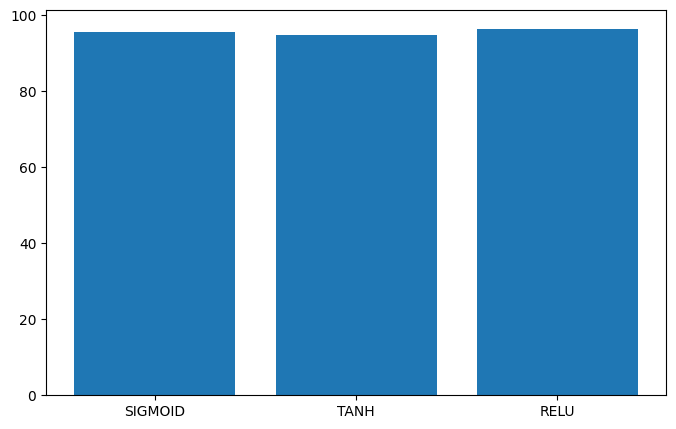

In [12]:
# 7. Display comparison table
results_df = pd.DataFrame(results)

print("\n========== PERFORMANCE COMPARISON ==========")
print(results_df.to_string(index=False))

# 8. Plot test accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(
    results_df['Activation'],
    results_df['Test Accuracy (%)']
)

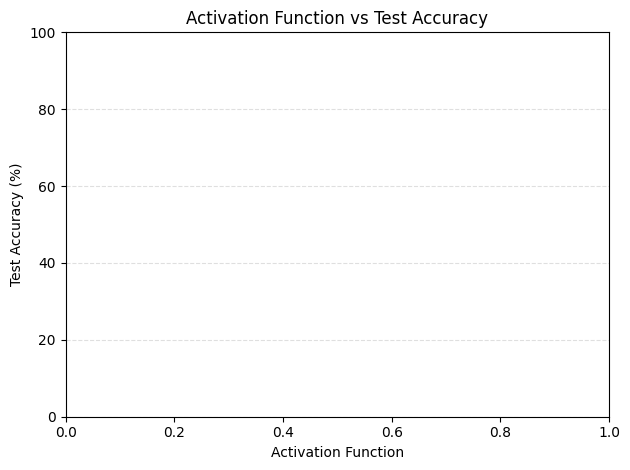

In [13]:
plt.title('Activation Function vs Test Accuracy')
plt.xlabel('Activation Function')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


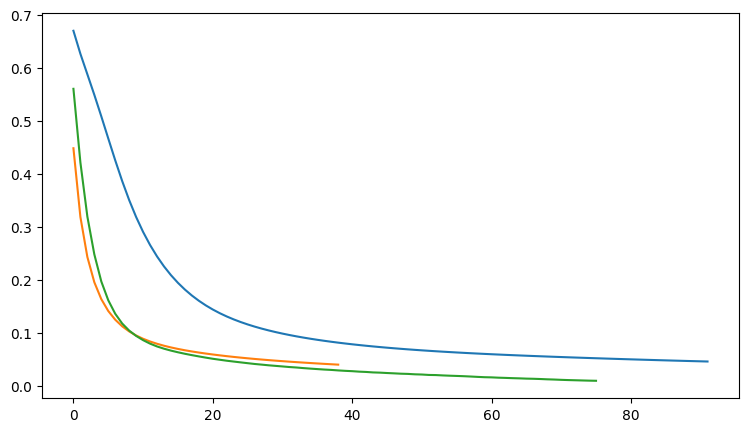

In [14]:
# 9. Plot training loss comparison
plt.figure(figsize=(9, 5))

for activation in activations:
    plt.plot(
        histories[activation]['loss'],
        label=activation.upper()
    )

C:\Users\khush\AppData\Local\Temp\ipykernel_12896\3584018126.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


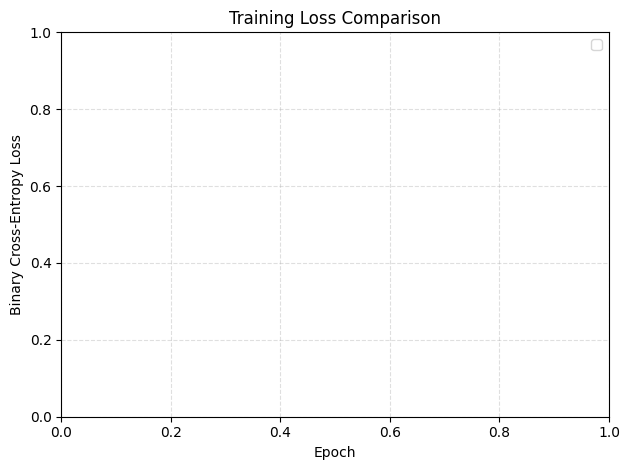

In [15]:
plt.title('Training Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


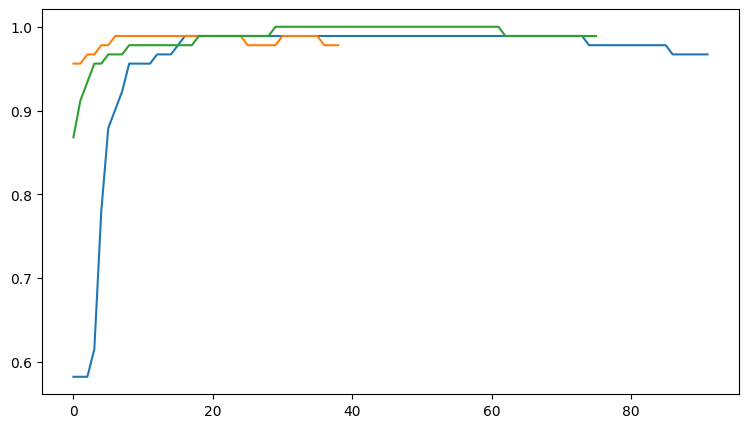

In [16]:
# 10. Plot validation accuracy comparison
plt.figure(figsize=(9, 5))

for activation in activations:
    plt.plot(
        histories[activation]['val_accuracy'],
        label=activation.upper()
    )

C:\Users\khush\AppData\Local\Temp\ipykernel_12896\1772704672.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


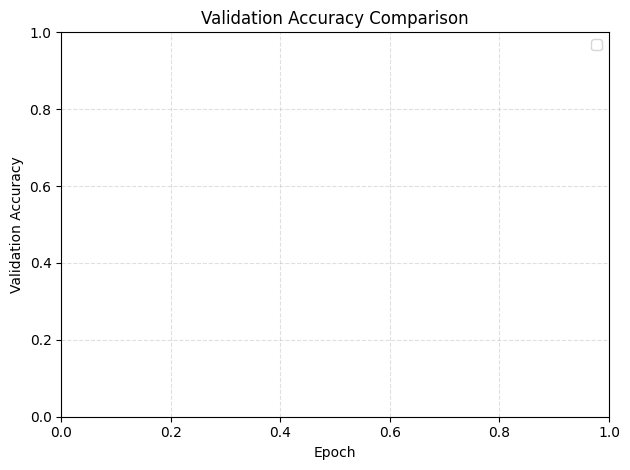

In [17]:
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
